# PyTorch Neural Network

## Goal

Build and evaluate a GPU-trained PyTorch neural network for predicting household `Global_active_power` 60 minutes into the future.

The neural network will be compared directly against the classical baseline models using the same chronological validation set and evaluation metrics.

## Current Model to Beat

Histogram Gradient Boosting currently has the best validation performance:

- RMSE: 0.7885
- MAE: 0.5264
- R²: 0.434
- RMSE improvement vs persistence: 26.4%

The neural network does not need to win for the project to be successful. The goal is to determine which model performs best based on evidence.

## Plan

1. Load the engineered household power dataset.
2. Recreate the same chronological train/validation/test split.
3. Fit feature scaling using the training set only.
4. Convert the datasets into PyTorch tensors.
5. Build `Dataset` and `DataLoader` objects.
6. Define a multi-layer perceptron for tabular regression.
7. Move the model and training batches to the GPU.
8. Train using:
   - MSE loss
   - Adam optimizer
   - mini-batches
   - learning-rate scheduling
   - early stopping
9. Track training and validation loss.
10. Restore the best validation model.
11. Generate validation predictions.
12. Evaluate using:
    - MAE
    - RMSE
    - R²
13. Compare neural-network performance with:
    - persistence
    - linear regression
    - random forest
    - histogram gradient boosting
14. Keep the test set untouched until final model selection.

## Key Questions

- Can the neural network outperform histogram gradient boosting?
- Does the network generalize well or begin to overfit?
- How much does GPU training help with this dataset size?
- Does the added complexity of deep learning provide enough performance improvement to justify using it?

In [2]:
# Load Data and Recreate the Chronological Split

from pathlib import Path

import numpy as np
import pandas as pd

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler

data_path = Path(
    "../data/processed/household_power_features.parquet"
)

df = pd.read_parquet(data_path)
df = df.sort_values("datetime").reset_index(drop=True)

print("Shape:", df.shape)
print("Start:", df["datetime"].min())
print("End:", df["datetime"].max())

Shape: (1950244, 24)
Start: 2006-12-17 17:23:00
End: 2010-11-26 20:02:00


In [3]:
#same split as the baseline

n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (1365170, 24)
Validation: (292537, 24)
Test: (292537, 24)


In [4]:
# same feature list

feature_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3",

    "power_lag_1",
    "power_lag_5",
    "power_lag_15",
    "power_lag_30",
    "power_lag_60",
    "power_lag_120",
    "power_lag_1380",

    "hour",
    "day_of_week",
    "month",
    "is_weekend",

    "rolling_mean_15",
    "rolling_mean_60",
    "rolling_std_60",
    "rolling_mean_1440"
]

target_col = "power_target_60"

In [5]:
#split predictors and target

X_train = train_df[feature_cols].copy()
y_train = train_df[target_col].copy()

X_val = val_df[feature_cols].copy()
y_val = val_df[target_col].copy()

X_test = test_df[feature_cols].copy()
y_test = test_df[target_col].copy()

In [6]:
# Scale Features Using Training Statistics Only

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [7]:
print("Train mean, first 5 features:")
print(X_train_scaled.mean(axis=0)[:5])

print("\nTrain std, first 5 features:")
print(X_train_scaled.std(axis=0)[:5])

Train mean, first 5 features:
[ 4.26376648e-17 -7.99456216e-17 -1.32176761e-15 -6.92862054e-17
  2.79809676e-17]

Train std, first 5 features:
[1. 1. 1. 1. 1.]


In [8]:
## recheck above when possible

In [9]:
# Convert to PyTorch Tensors

In [10]:
X_train_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

X_val_tensor = torch.tensor(
    X_val_scaled,
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

In [11]:
print("X train:", X_train_tensor.shape)
print("y train:", y_train_tensor.shape)

print("X val:", X_val_tensor.shape)
print("y val:", y_val_tensor.shape)

print("X test:", X_test_tensor.shape)
print("y test:", y_test_tensor.shape)

X train: torch.Size([1365170, 22])
y train: torch.Size([1365170, 1])
X val: torch.Size([292537, 22])
y val: torch.Size([292537, 1])
X test: torch.Size([292537, 22])
y test: torch.Size([292537, 1])


In [12]:
# Create PyTorch Datasets and DataLoaders

In [13]:
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

In [14]:
batch_size = 2048

In [15]:
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=True
)

In [16]:
# single batch inspection

xb, yb = next(iter(train_loader))

print("Feature batch shape:", xb.shape)
print("Target batch shape:", yb.shape)
print("Feature dtype:", xb.dtype)
print("Target dtype:", yb.dtype)


Feature batch shape: torch.Size([2048, 22])
Target batch shape: torch.Size([2048, 1])
Feature dtype: torch.float32
Target dtype: torch.float32


In [17]:
# Define the Tabular MLP

In [18]:
class TabularMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.10),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)

In [19]:
# ## 6. Move the Model to the GPU

In [20]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


In [21]:
# instantiate the nn

input_dim = X_train_tensor.shape[1]

model = TabularMLP(input_dim=input_dim).to(device)

print(model)

TabularMLP(
  (network): Sequential(
    (0): Linear(in_features=22, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.1, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): ReLU()
    (10): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [22]:
# inspect train parameter count

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 13,697
Trainable parameters: 13,697


In [23]:
# inspect parameter shapes

for name, param in model.named_parameters():
    print(f"{name:35s} {tuple(param.shape)}")

network.0.weight                    (128, 22)
network.0.bias                      (128,)
network.1.weight                    (128,)
network.1.bias                      (128,)
network.4.weight                    (64, 128)
network.4.bias                      (64,)
network.5.weight                    (64,)
network.5.bias                      (64,)
network.8.weight                    (32, 64)
network.8.bias                      (32,)
network.10.weight                   (1, 32)
network.10.bias                     (1,)


In [24]:
## 7. Configure Loss Function, Optimizer, and Scheduler

In [25]:
# regression
criterion = nn.MSELoss()

In [26]:
# adam with mild weight decay

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-5
)

In [27]:
# validation loss to reduce learning rate when prog stalls

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=5
)

In [28]:
# initial settings

max_epochs = 100
early_stopping_patience = 10

In [29]:
# prepare the training loop

import copy
import time

In [30]:
def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    device,
    max_epochs=100,
    early_stopping_patience=10,
):

    history = {
        "train_loss": [],
        "val_loss": [],
        "learning_rate": []
    }

    best_val_loss = float("inf")
    best_model_state = copy.deepcopy(model.state_dict())

    epochs_without_improvement = 0

    for epoch in range(max_epochs):

        epoch_start = time.time()

        # -----------------------
        # Training phase
        # -----------------------
        model.train()

        train_loss_sum = 0.0
        train_samples = 0

        for xb, yb in train_loader:

            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            optimizer.zero_grad()

            predictions = model(xb)

            loss = criterion(predictions, yb)

            loss.backward()

            optimizer.step()

            batch_size_actual = xb.size(0)

            train_loss_sum += loss.item() * batch_size_actual
            train_samples += batch_size_actual

        train_loss = train_loss_sum / train_samples

        # -----------------------
        # Validation phase
        # -----------------------
        model.eval()

        val_loss_sum = 0.0
        val_samples = 0

        with torch.no_grad():

            for xb, yb in val_loader:

                xb = xb.to(device, non_blocking=True)
                yb = yb.to(device, non_blocking=True)

                predictions = model(xb)

                loss = criterion(predictions, yb)

                batch_size_actual = xb.size(0)

                val_loss_sum += loss.item() * batch_size_actual
                val_samples += batch_size_actual

        val_loss = val_loss_sum / val_samples

        # -----------------------
        # Learning-rate scheduler
        # -----------------------
        scheduler.step(val_loss)

        current_lr = optimizer.param_groups[0]["lr"]

        # -----------------------
        # Store training history
        # -----------------------
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["learning_rate"].append(current_lr)

        # -----------------------
        # Early stopping
        # -----------------------
        if val_loss < best_val_loss:

            best_val_loss = val_loss

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

        elapsed = time.time() - epoch_start

        print(
            f"Epoch {epoch + 1:3d}/{max_epochs} | "
            f"Train Loss: {train_loss:.6f} | "
            f"Val Loss: {val_loss:.6f} | "
            f"LR: {current_lr:.2e} | "
            f"Time: {elapsed:.1f}s"
        )

        if epochs_without_improvement >= early_stopping_patience:

            print("\nEarly stopping triggered.")
            break

    # Restore best model
    model.load_state_dict(best_model_state)

    print(
        f"\nBest validation MSE: "
        f"{best_val_loss:.6f}"
    )

    return model, history

In [31]:
# double check nn

xb, yb = next(iter(train_loader))

xb = xb.to(device)
yb = yb.to(device)

with torch.no_grad():
    preds = model(xb)

print("Input shape:", xb.shape)
print("Prediction shape:", preds.shape)
print("Target shape:", yb.shape)

Input shape: torch.Size([2048, 22])
Prediction shape: torch.Size([2048, 1])
Target shape: torch.Size([2048, 1])


In [32]:
# train the neural network

model, history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    device=device,
    max_epochs=max_epochs,
    early_stopping_patience=early_stopping_patience
)

Epoch   1/100 | Train Loss: 0.784913 | Val Loss: 0.691765 | LR: 1.00e-03 | Time: 7.3s
Epoch   2/100 | Train Loss: 0.701269 | Val Loss: 0.661253 | LR: 1.00e-03 | Time: 7.3s
Epoch   3/100 | Train Loss: 0.678732 | Val Loss: 0.648483 | LR: 1.00e-03 | Time: 7.2s
Epoch   4/100 | Train Loss: 0.664761 | Val Loss: 0.640230 | LR: 1.00e-03 | Time: 7.2s
Epoch   5/100 | Train Loss: 0.656785 | Val Loss: 0.640553 | LR: 1.00e-03 | Time: 7.2s
Epoch   6/100 | Train Loss: 0.650512 | Val Loss: 0.640662 | LR: 1.00e-03 | Time: 7.5s
Epoch   7/100 | Train Loss: 0.645908 | Val Loss: 0.641050 | LR: 1.00e-03 | Time: 7.4s
Epoch   8/100 | Train Loss: 0.641796 | Val Loss: 0.638772 | LR: 1.00e-03 | Time: 7.4s
Epoch   9/100 | Train Loss: 0.637901 | Val Loss: 0.638119 | LR: 1.00e-03 | Time: 7.5s
Epoch  10/100 | Train Loss: 0.635110 | Val Loss: 0.640548 | LR: 1.00e-03 | Time: 7.4s
Epoch  11/100 | Train Loss: 0.632008 | Val Loss: 0.637278 | LR: 1.00e-03 | Time: 7.5s
Epoch  12/100 | Train Loss: 0.629196 | Val Loss: 0.645

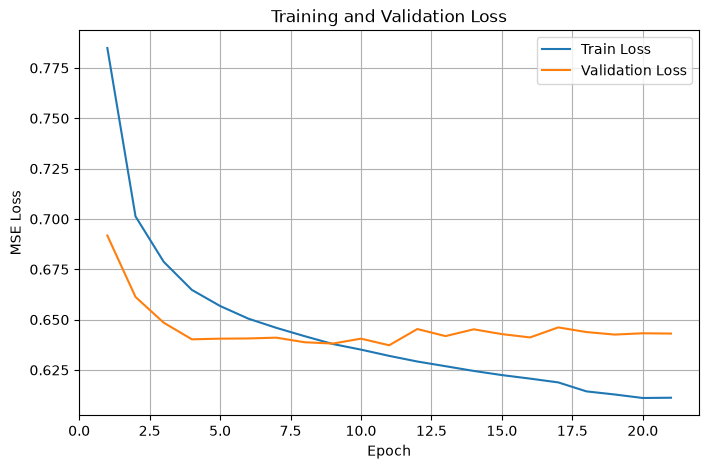

In [33]:
# inspect training and validation loss

import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], label="Train Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [34]:
# Evaluate the Best Model on the Validation Set

In [35]:
model.eval()

val_predictions = []
val_targets = []

with torch.no_grad():

    for xb, yb in val_loader:

        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        preds = model(xb)

        val_predictions.append(
            preds.cpu().numpy()
        )

        val_targets.append(
            yb.cpu().numpy()
        )

In [36]:
# combine batches
val_predictions = np.concatenate(
    val_predictions
).ravel()

val_targets = np.concatenate(
    val_targets
).ravel()


In [37]:
# calculate same metrics as classical models

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

nn_mae = mean_absolute_error(
    val_targets,
    val_predictions
)

nn_rmse = mean_squared_error(
    val_targets,
    val_predictions
) ** 0.5

nn_r2 = r2_score(
    val_targets,
    val_predictions
)

print(f"Neural Network MAE:  {nn_mae:.4f}")
print(f"Neural Network RMSE: {nn_rmse:.4f}")
print(f"Neural Network R²:   {nn_r2:.4f}")

Neural Network MAE:  0.5210
Neural Network RMSE: 0.7983
Neural Network R²:   0.4201


In [38]:
#compare
best_baseline_rmse = 0.7885

improvement_vs_hgb = (
    (best_baseline_rmse - nn_rmse)
    / best_baseline_rmse
) * 100

print(
    f"NN RMSE improvement vs HGB: "
    f"{improvement_vs_hgb:.2f}%"
)

NN RMSE improvement vs HGB: -1.24%


In [40]:
# ^^ gradient boosting is still better than neural network at this point (negative number)

In [41]:
## compare predictions with actual values

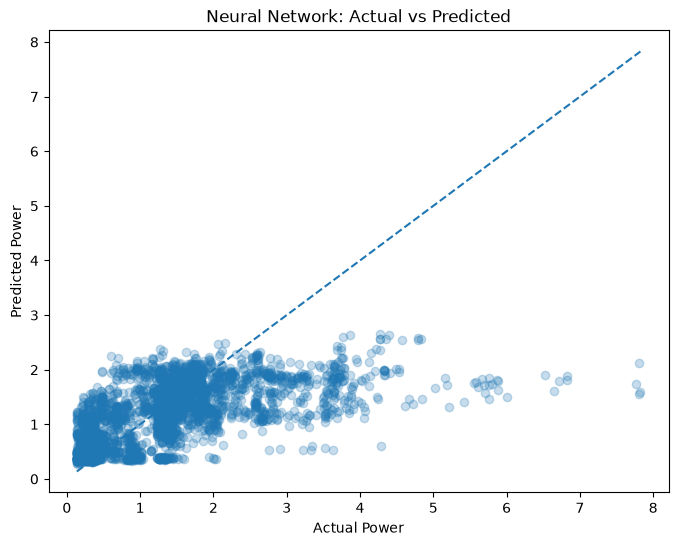

In [42]:
sample_size = 5000

plt.figure(figsize=(8, 6))
plt.scatter(
    val_targets[:sample_size],
    val_predictions[:sample_size],
    alpha=0.25
)

min_val = min(
    val_targets[:sample_size].min(),
    val_predictions[:sample_size].min()
)

max_val = max(
    val_targets[:sample_size].max(),
    val_predictions[:sample_size].max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual Power")
plt.ylabel("Predicted Power")
plt.title("Neural Network: Actual vs Predicted")
plt.show()

### Neural Network Validation Interpretation

The PyTorch neural network achieved validation performance close to the strongest
classical model, but did not outperform Histogram Gradient Boosting.

The neural network RMSE was approximately 1.24% worse than the HGB benchmark,
indicating that the added model complexity did not produce a validation advantage
for this structured tabular forecasting problem.

The actual-vs-predicted plot also shows that the neural network tends to regress
extreme power values toward the center of the prediction distribution. Predictions
track the dense range of household power consumption reasonably well, but large
power spikes are systematically underpredicted.

This suggests that rare high-consumption periods are more difficult for the MLP
to model than the dominant operating regime.

Overall, the result supports evidence-based model selection: for the current
features and forecasting horizon, Histogram Gradient Boosting remains the preferred
model.